# MNIST — a convolutional network in four stages

The workflow diagram this notebook implements has seven blocks, grouped into four stages.
The diagram is drawn for a dense **ANN** — it names no layer types, no kernel sizes, no
input shapes — so *every* convolutional decision below is ours, and each one is stated and
justified in-cell before it is used. The dense-ANN version of the same four stages lives in
`output/mnist_ann_clean.ipynb`; this notebook reuses its framing but replaces `Flatten` at
the front with learned local filters.

| Diagram block | Implemented in (cell) | Where the evidence is |
|---|---|---|
| 1 · Load MNIST dataset | Stage 1 setup + load cells | raw `(60000,28,28)` uint8; channel-axis reshape; asserts |
| 2 · Prepare Sequential model | Stage 2 `build_cnn()` | `model.summary()`; per-layer shape walk |
| 3 · The architecture itself (our choice, CNN) | Stage 2 — conv semantics + locality cells | output-size formula checked layer by layer; weight-share probe; size-independent conv params |
| 4 · Weight initialisation — He Normal for ReLU | Stage 3a | measured kernel std vs `sqrt(2/fan_in)`; activation RMS vs Glorot |
| 5 · L2 regularisation — penalise large weights | Stage 3b | `evaluate()` loss split into cross-entropy + explicit `λ·Σw²`, matched numerically |
| 6 · BatchNorm + Dropout regularisation | Stage 3c / 3d | BN momentum transient measured; spatial-vs-unit dropout and train-vs-inference paths measured |
| 7 · Fit the model, evaluate on train **and** test | Stage 4 | curves, train/val/test table, CE-vs-L2 split, confusion matrix, ablation |

CPU only (2 cores, ~3 GB RAM), ~4.5 minutes end-to-end on this machine. Data budget is deliberately small:
20 000 fit samples, 10 000 validation carved from the *train* pool, the 10 000 test images
untouched until the final evaluation. Expect test accuracy ≈ 0.98 with 422,314 `count_params`
(both are measured below, not asserted). `SEED = 42` makes reruns comparable.
---

In [1]:
from __future__ import annotations
import os, re, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, SpatialDropout2D,
                                     BatchNormalization, Activation, Flatten,
                                     Dense, Dropout)
from tensorflow.keras.initializers import HeNormal, GlorotUniform
from tensorflow.keras.regularizers import L2
from sklearn.metrics import classification_report, confusion_matrix

# ---- single source of truth for every hyper-parameter -------------------------
SEED             = 42
L2_SCALE         = 1e-4     # weight-decay strength (light 1e-5 .. heavy 1e-3)
DROPOUT          = 0.5      # unit-drop rate after the Dense head block
SPATIAL_DROPOUT  = 0.25     # whole-channel drop rate after each conv block
BATCH_SIZE       = 128      # not free: BatchNorm estimates stats per batch
EPOCHS           = 12       # budget cap; EarlyStopping(patience=6) may fire earlier
N_FIT            = 20_000   # of the 60k train pool; keeps an epoch around 9 s
N_VAL            = 10_000   # also from the train pool - never from test
N_CLASSES        = 10

keras.utils.set_random_seed(SEED)
tf.random.set_seed(SEED)
print("tensorflow", tf.__version__, "| keras", keras.__version__,
      "| gpu", "on" if tf.config.list_physical_devices("GPU") else "off")

tensorflow 2.21.0 | keras 3.15.1 | gpu off


## Stage 1 — Load the MNIST dataset

`keras.datasets.mnist.load_data()` hands back `(60000, 28, 28)` uint8 images (0..255) with
integer labels, plus a `(10000, 28, 28)` test split. Three transforms matter for a CNN:

- **Add a channel axis.** A `Conv2D` kernel has shape `(kh, kw, C_in, C_out)`; it *must*
  know how many input channels to match against. Keras uses channels-last, so the images
  become `(60000, 28, 28, 1)` via `x[..., None]` — the `1` is the greyscale channel count.
  The dense notebook could skip this because `Flatten` does not care about axis order.
- **Scale to float32 / 255.** Feeding 0..255 makes early outputs enormous, gradients erratic,
  and BatchNorm's per-batch statistics dominated by scale rather than content.
- **One-hot the labels** to pair with `softmax` + `categorical_crossentropy`. Mixing the two
  by accident (integer labels into a categorical loss) is the classic Stage-1 failure.

In [2]:
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = keras.datasets.mnist.load_data()

print(f"train {x_train_raw.shape} {x_train_raw.dtype}   "
      f"test {x_test_raw.shape} {x_test_raw.dtype}")
print(f"pixels {x_train_raw.min()}..{x_train_raw.max()} (uint8, not normalised yet)")
print(f"labels train {sorted(set(y_train_raw.tolist()))}")

# No channel axis yet: 3 dims, and the last one is width, not channels.
assert x_train_raw.ndim == 3 and x_train_raw.shape[1:] == (28, 28)

train (60000, 28, 28) uint8   test (10000, 28, 28) uint8
pixels 0..255 (uint8, not normalised yet)
labels train [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [3]:
def preprocess(x, y):
    # x[..., None] inserts the channels-last axis that Conv2D insists on;
    # dividing by 255 puts every pixel (and therefore every conv response) in [0, 1].
    x4 = x[..., None].astype("float32") / 255.0
    return x4, keras.utils.to_categorical(y, N_CLASSES)

x_train, y_train = preprocess(x_train_raw, y_train_raw)
x_test,  y_test  = preprocess(x_test_raw,  y_test_raw)

print(f"x_train {x_train.shape} {x_train.dtype}  range {x_train.min():.1f}..{x_train.max():.1f}")
assert x_train.shape == (60_000, 28, 28, 1) and x_train.dtype == np.float32
assert x_train.max() <= 1.0
assert y_train.shape == (60_000, 10) and y_train.sum(1).mean() == 1.0
print(f"one-hot of raw label {y_train_raw[0]} -> {y_train[0].astype(int).tolist()}")

x_train (60000, 28, 28, 1) float32  range 0.0..1.0
one-hot of raw label 5 -> [0, 0, 0, 0, 0, 1, 0, 0, 0, 0]


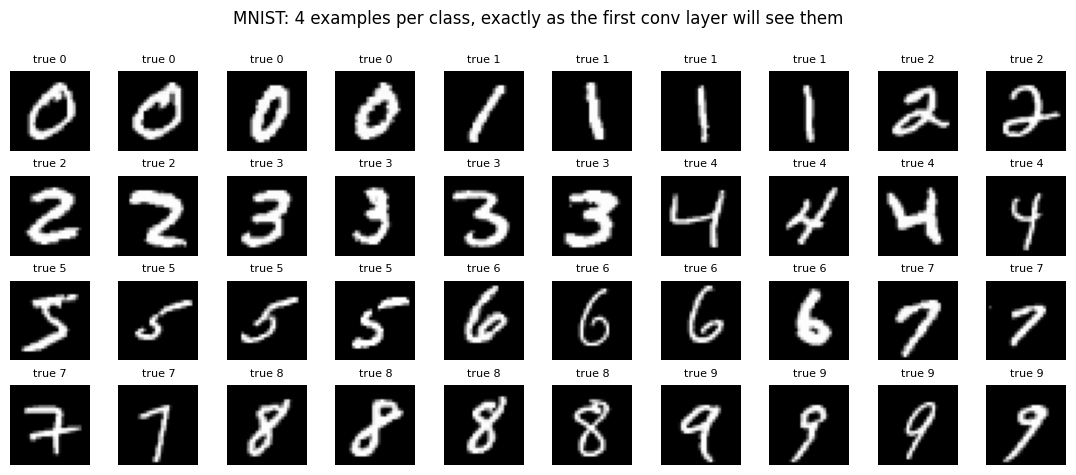

In [4]:
# Confirm the arrays really are digits before spending minutes training on them.
fig, axes = plt.subplots(4, 10, figsize=(11, 4.7))
for k, ax in enumerate(axes.ravel()):
    cls, slot = divmod(k, 4)                       # 4 examples per class
    idx = np.where(y_train_raw == cls)[0][slot]
    ax.imshow(x_train_raw[idx], cmap="gray")
    ax.set_title(f"true {y_train_raw[idx]}", fontsize=8)
    ax.axis("off")
fig.suptitle("MNIST: 4 examples per class, exactly as the first conv layer will see them",
             y=1.0)
plt.tight_layout(); plt.show()

## Stage 2 — Prepare the Sequential model (the CNN is our choice, so justify it)

```
Input(28,28,1)
  Conv2D(32,3,same,no-bias,He,L2) -> BN -> relu -> MaxPool(2) -> SpatialDropout2D(.25)
  Conv2D(64,3,same,no-bias,He,L2) -> BN -> relu -> MaxPool(2) -> SpatialDropout2D(.25)
  Flatten -> Dense(128,no-bias,He,L2) -> BN -> relu -> Dropout(.5)
  -> Dense(10, softmax, He, L2)
```

Why a CNN and not the diagram's literal dense reading: a `Dense` over 784 pixels ties every
weight to one fixed pixel position, so a digit shifted by two pixels is a completely
different input vector. A conv kernel is a *learned local template* slid across the image —
one weight set sees every position (weight sharing), each output unit only ever looks at a
small neighbourhood (weight locality), and the parameter count stops depending on image
size. Two 3×3 convs then two more, with 2×2 pools between, are enough for MNIST because
a pool broadens each unit's view without adding parameters. Each shape/layer decision is
verified cell by cell below, not taken on faith.

The builder is **parametrised on purpose** (`l2`, `dropout`, `spatial_dropout`, `use_bn`,
`momentum`): Stage 3c needs otherwise identical models with a different BN momentum and the
ablation needs the regularisers off, and one function taking flags is far less error-prone
than hand-copied architectures that silently drift apart.

In [5]:
def build_cnn(l2=L2_SCALE, dropout=DROPOUT, spatial_dropout=SPATIAL_DROPOUT,
              use_bn=True, momentum=0.99, input_shape=(28, 28, 1),
              seed=SEED, name="mnist_cnn"):
    # Conv blocks keep activation=None: BN must see the raw linear response, and ReLU
    # must be an explicit layer *after* BN, otherwise BN would normalise clipped outputs.
    # use_bias=False everywhere a BN follows - see the absorption demo two cells later.
    def conv_block(i, filters):
        blk = [Conv2D(filters, 3, padding="same", use_bias=False, activation=None,
                      kernel_initializer=HeNormal(seed=seed),
                      kernel_regularizer=L2(l2) if l2 else None,
                      name=f"conv_{i}")]
        if use_bn:
            blk.append(BatchNormalization(momentum=momentum, name=f"bn_{i}"))
        blk += [Activation("relu", name=f"relu_{i}"),
               MaxPooling2D(2, name=f"pool_{i}")]
        if spatial_dropout is not None:
            blk.append(SpatialDropout2D(spatial_dropout, seed=seed, name=f"sdrop_{i}"))
        return blk

    layers = [Input(shape=input_shape)]
    layers += conv_block(1, 32) + conv_block(2, 64)
    layers += [Flatten(name="flatten")]
    layers += [Dense(128, use_bias=False,
                     kernel_initializer=HeNormal(seed=seed),
                     kernel_regularizer=L2(l2) if l2 else None, name="dense_128")]
    if use_bn:
        layers.append(BatchNormalization(momentum=momentum, name="bn_head"))
    layers += [Activation("relu", name="relu_head")]
    if dropout is not None:
        layers.append(Dropout(dropout, name="drop_head"))
    layers += [Dense(N_CLASSES, activation="softmax",
                     kernel_initializer=HeNormal(seed=seed),
                     kernel_regularizer=L2(l2) if l2 else None, name="head")]
    # a Sequential/Model name becomes a TF variable scope: spaces are rejected, hence slugs
    return keras.Sequential(layers, name=re.sub(r"[^A-Za-z0-9_]+", "_", name))


def compile_cnn(m):
    # KEYWORDS ONLY. Keras 3's Model.compile signature is
    # (optimizer, loss, loss_weights, metrics, ...) - a 3rd positional argument would be
    # read as loss_weights and explode with "dtype='string' is not a valid dtype for
    # Keras type promotion". Same trap in every compile call in this notebook.
    m.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return m


model = compile_cnn(build_cnn())
model.summary()

Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sdrop_1 (SpatialDropout2D)      │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sdrop_2 (SpatialDropout2D)      │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       401,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_head (BatchNormalization)    │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_head (Activation)          │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_head (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,314 (1.61 MB)

 Trainable params: 421,866 (1.61 MB)

 Non-trainable params: 448 (1.75 KB)

### What a Conv2D layer actually is

A convolution learns `C_out` **filters** (kernels). Each filter is a small `3×3` window over
*all* input channels; its shape in memory is `(kh, kw, C_in, C_out)` — note `C_in` third,
`C_out` fourth. The filter is slid over the image with **strides** `s` (how many pixels
between steps) and **padding** `p`:

| mode | what it does | output side (input `H`, kernel `k`, stride `s`) |
|---|---|---|
| `"valid"` | no padding, only fully-covered positions | `floor((H - k)/s) + 1` |
| `"same"` | zero-pad so a stride-1 output keeps `H` | `floor((H + 2p - k)/s) + 1`, p chosen to hold H |

The same general formula `floor((H + 2p - k)/s) + 1` also gives max-pool sizes (pad 0).
Two consequences worth fixing in memory:

- **Weight sharing.** The kernel is applied at every position with *no* per-position copy.
  A position is not a parameter, which is why a conv layer's parameter count is
  `kh·kw·C_in·C_out` (+ bias) and does **not** depend on image size: `3·3·1·32 = 288`
  weights see a `28×28` or a `1000×1000` image equally.
- **Receptive field.** Each first-layer unit sees 9 input pixels; after pool-conv-pool
  the second block's units see a much larger patch of the *original* image through
  composition, not through more weights per unit.

`MaxPooling2D(2)` then keeps the max of each non-overlapping 2×2 window — half the spatial
resolution, a small translation tolerance, *zero* learned parameters. `Flatten` unrolls the
final `7×7×64` feature map into a `3136`-wide vector; `3136 = 7·7·64` is exactly why this
one layer is the only place the architecture still depends on image size — from there the
`Dense(128)` head and softmax treat it as an ordinary ANN, which is where the dense
notebook's four ingredients (He, L2, BN, Dropout) continue to apply unchanged.

In [6]:
# Shape walk: feed a zero batch through every layer in order and check the analytic
# output-size formula against what the layer really produced.
# NOTE Sequential.layers EXCLUDES the InputLayer, so layers[0] is conv_1, not the input.
probe = build_cnn(name="shape_probe")
h = tf.zeros((3, 28, 28, 1), "float32")
print(f"{'layer':11s} {'type':18s} {'config':44s} {'out':16s} formula-check")
print("-" * 108)
for l in probe.layers:
    in_hw = int(h.shape[1]) if h.shape.rank == 4 else 0
    in_c  = int(h.shape[3]) if h.shape.rank == 4 else int(h.shape[-1])
    h = l(h, training=False)                    # BN in inference mode: shapes are identical
    out = tuple(int(v) for v in h.shape)
    cfg, chk = l.get_config(), ""
    if isinstance(l, (Conv2D, MaxPooling2D)):
        if isinstance(l, Conv2D):
            k, s = cfg["kernel_size"][0], cfg["strides"][0]
            same = cfg["padding"] == "same"
            desc_mode = cfg["padding"]
        else:
            k, s, same, desc_mode = cfg["pool_size"][0], cfg["strides"][0], False, "valid"
        # total pad added by "same" (split over the two sides, +-1 if odd):
        total = max(((in_hw + s - 1) // s - 1) * s + k - in_hw, 0) if same else 0
        exp = (in_hw + total - k) // s + 1
        ok = "OK" if exp == out[1] else f"MISMATCH exp={exp}"
        chk = f"k={k} s={s} {desc_mode} -> floor(({in_hw}+{total}-{k})/{s})+1={exp} {ok}"
    elif isinstance(l, BatchNormalization):
        chk = f"momentum={cfg['momentum']}, stats over N,H,W per channel"
    elif isinstance(l, SpatialDropout2D):
        chk = f"rate={cfg['rate']} whole-channel"
    elif isinstance(l, Flatten):
        chk = f"{in_hw}x{in_hw}x{in_c} unrolled -> {out[1]}" + (
              "  (=7*7*64 OK)" if out[1] == 3136 else "")
    elif isinstance(l, Dense):
        chk = f"units={cfg['units']} act={cfg['activation']}"
    elif isinstance(l, Activation):
        chk = cfg["activation"]
    print(f"{cfg['name']:11s} {type(l).__name__:18s} {chk:44s} {str(out):16s}")
print(f"\nwalk ends at {tuple(int(v) for v in h.shape)} -> probabilities over 10 classes")
assert tuple(int(v) for v in h.shape) == (3, 10)
print(f"layers seen: {len(probe.layers)} - the Input tensor is NOT among them.")

layer       type               config                                       out              formula-check
------------------------------------------------------------------------------------------------------------
conv_1      Conv2D             k=3 s=1 same -> floor((28+2-3)/1)+1=28 OK    (3, 28, 28, 32) 
bn_1        BatchNormalization momentum=0.99, stats over N,H,W per channel  (3, 28, 28, 32) 
relu_1      Activation         relu                                         (3, 28, 28, 32) 
pool_1      MaxPooling2D       k=2 s=2 valid -> floor((28+0-2)/2)+1=14 OK   (3, 14, 14, 32) 
sdrop_1     SpatialDropout2D   rate=0.25 whole-channel                      (3, 14, 14, 32) 
conv_2      Conv2D             k=3 s=1 same -> floor((14+2-3)/1)+1=14 OK    (3, 14, 14, 64) 
bn_2        BatchNormalization momentum=0.99, stats over N,H,W per channel  (3, 14, 14, 64) 
relu_2      Activation         relu                                         (3, 14, 14, 64) 
pool_2      MaxPooling2D       k=2 s=2 v

In [7]:
# Two locality claims, checked rather than asserted.
# (1) Weight sharing: one fixed 3x3 kernel must fire identically wherever the pattern sits.
shared = Conv2D(1, 3, padding="valid", use_bias=False, activation=None, name="shared_probe")
shared.build((None, 28, 28, 1))                     # kernel variable created, shape (3,3,1,1)
w = np.zeros((3, 3, 1, 1), "float32"); w[1, 1, 0, 0] = 1.0     # center-tap filter
shared.kernel.assign(w)
img_a = np.zeros((1, 28, 28, 1), "float32"); img_a[0, 10, 5, 0] = 7.0
img_b = np.zeros_like(img_a);                 img_b[0, 20, 15, 0] = 7.0
oa, ob = np.asarray(shared(img_a)).ravel(), np.asarray(shared(img_b)).ravel()
ia, ib = int(np.argmax(oa)), int(np.argmax(ob))
print(f"peak response at flat index {ia} vs {ib}: values {oa[ia]:.1f} vs {ob[ib]:.1f}; "
      f"one weight set, peak shifted by {ib - ia} = 10 rows x 26 cols + 10 cols.")
assert oa[ia] == ob[ib] == 7.0 and (ib - ia) == 10 * 26 + 10

# (2) Size independence of the CONV parameters: rebuild the stack for a 14x14 image.
small = build_cnn(input_shape=(14, 14, 1), name="small_cnn")
c1_big = int(np.prod(model.layers[0].kernel.shape))      # layers[0] == conv_1
c1_small = int(np.prod(small.layers[0].kernel.shape))
print(f"conv_1 params on a 28x28 model: {c1_big}, on a 14x14 model: {c1_small} -> identical")
assert c1_big == c1_small == 288                          # 3*3*1*32, no image size anywhere
flat_big = int(model.get_layer("dense_128").kernel.shape[0])
flat_small = int(small.get_layer("dense_128").kernel.shape[0])
print(f"only the Flatten width changes: {flat_big} (=7*7*64) vs {flat_small} (=3*3*64), so")
print(f"dense_128 has {flat_big*128:,} weights on 28x28 but {flat_small*128:,} on 14x14 -")
print("image-size dependence survives only into the head, exactly where the CNN stops being local.")

peak response at flat index 238 vs 508: values 7.0 vs 7.0; one weight set, peak shifted by 270 = 10 rows x 26 cols + 10 cols.
conv_1 params on a 28x28 model: 288, on a 14x14 model: 288 -> identical
only the Flatten width changes: 3136 (=7*7*64) vs 576 (=3*3*64), so
dense_128 has 401,408 weights on 28x28 but 73,728 on 14x14 -
image-size dependence survives only into the head, exactly where the CNN stops being local.


### Two accounting details before we count parameters

**Why `use_bias=False` wherever BatchNorm follows.** A conv bias adds the *same* constant to
every output of one feature map. BatchNorm then subtracts that map's mean — the constant is
gone before ReLU ever sees it — and adds back its own trainable offset `β`. The conv bias can
therefore never influence the function that training can express; it only slows fitting and
wastes parameters. The next cell proves it numerically: a conv followed by BN returns
*identical* activations for two different constant biases.

**Where the parameters actually live.** Trainable = conv/dense kernels (never biases under
BN) + BN `γ/β`. Non-trainable = BN `moving_mean/moving_variance`, plus a two-integer
`seed_generator_state` buffer attached to every seeded layer — buffers Keras adds because we
passed `seed=` to `HeNormal`/`Dropout`. `count_params()` deliberately excludes those RNG
states, so summing *all* variables gives a slightly larger number, and printing both is the
only honest way to reconcile them. The cell after the proof sums each bucket independently.

In [8]:
# Proof: a constant conv bias is annihilated by the BatchNorm that follows it.
kern = tf.random.stateless_normal((3, 3, 1, 4), seed=(SEED, 7))   # one shared kernel
c0 = Conv2D(4, 3, padding="same", use_bias=True, activation=None, name="bias_A")
c5 = Conv2D(4, 3, padding="same", use_bias=True, activation=None, name="bias_B")
c0.build((None, 28, 28, 1)); c5.build((None, 28, 28, 1))
c0.set_weights([kern.numpy(), np.zeros(4, "float32")])            # bias = 0
c5.set_weights([kern.numpy(), np.full(4, 3.0, "float32")])        # bias = 3
m0 = keras.Sequential([Input((28, 28, 1)), c0, BatchNormalization(name="bnA")])
m5 = keras.Sequential([Input((28, 28, 1)), c5, BatchNormalization(name="bnB")])
xb = x_train[:64]
# training=True forces BN to standardise with the BATCH statistics - which contain the
# bias, so it cancels. (On the inference path stale moving stats would NOT cancel it -
# that is precisely why the bias is redundant while BN is in the graph.)
ya = np.asarray(m0(xb, training=True)); yb = np.asarray(m5(xb, training=True))
d = float(np.abs(ya - yb).max()) / float(np.abs(ya).std() + 1e-12)
print(f"max |output(bias=0) - output(bias=3)| on the batch path: "
      f"{np.abs(ya - yb).max():.2e}  ({d:.1e} of one output std)")
assert d < 1e-3   # differ at most at the float32 round-off of a cancelled mean
print("identical -> the bias cannot change a function BN can already re-centre; the "
      "trainable BN beta is that offset instead. Dropping conv biases saves 32+64=96 params.")

max |output(bias=0) - output(bias=3)| on the batch path: 3.58e-05  (4.6e-05 of one output std)
identical -> the bias cannot change a function BN can already re-centre; the trainable BN beta is that offset instead. Dropping conv biases saves 32+64=96 params.


In [9]:
# Parameter accounting, bucket by bucket. Keras 3 has two subtleties that explain why the
# three totals below do NOT agree with each other:
#   * BatchNormalization's gamma/beta ARE trainable; its moving_mean/moving_variance are NOT.
#   * count_params() = trainable + BN moving stats, but it EXCLUDES the 2-int
#     `seed_generator_state` buffer that every seeded layer (Dropout/SpatialDropout2D)
#     carries. So summing *all* Keras variables is a couple of integers MORE than
#     count_params(), and the gap is exactly the RNG state.
def vsz(vs):
    return sum(int(np.prod(v.shape)) for v in vs)
per_layer = {}
for l in model.layers:
    t, n = vsz(l.trainable_variables), vsz(l.non_trainable_variables)
    if t + n:
        per_layer[l.name] = (t, n)
trainable   = vsz(model.trainable_variables)
moving      = sum(vsz([v for v in l.non_trainable_variables
                      if "moving" in v.name]) for l in model.layers
                 if isinstance(l, BatchNormalization))
seed_state  = sum(vsz([v for v in l.non_trainable_variables
                      if "seed_generator" in v.name]) for l in model.layers)
count_p     = model.count_params()
all_vars    = vsz(model.variables)

print(f"{'layer':11s} {'trainable':>10s} {'non-train':>10s}")
for k, (t, n) in per_layer.items():
    print(f"{k:11s} {t:>10,} {n:>10,}")
print("-" * 33)
print(f"{'TOTAL':11s} {trainable:>10,} {moving + seed_state:>10,}")
print(f"\ntrainable (weights + BN gamma/beta)          {trainable:>9,}")
print(f"BN moving stats (non-trainable)                 {moving:>9,}")
print(f"per-layer RNG state (excluded everywhere)       {seed_state:>9,}")
print(f"count_params() = trainable + moving             {count_p:>9,}")
print(f"sum of ALL model.variables = count + RNG        {all_vars:>9,}"
      f"   (+{all_vars - count_p} = the RNG state)")
assert trainable + moving == count_p
assert all_vars - count_p == seed_state
ksum = 288 + 18432 + 401408 + 1280 + 10
print(f"\nkernels only (3*3*1*32 + 3*3*32*64 + 3136*128 + 128*10 + 10 bias) = {ksum:,}")
print("The dense head's 401,408 weights are 95% of the model and are the ONLY part "
      "that still depends on the image size (7*7*64 inputs). That is the CNN argument in one number.")

layer        trainable  non-train
conv_1             288          0
bn_1                64         64
sdrop_1              0          2
conv_2          18,432          0
bn_2               128        128
sdrop_2              0          2
dense_128      401,408          0
bn_head            256        256
drop_head            0          2
head             1,290          0
---------------------------------
TOTAL          421,866        454

trainable (weights + BN gamma/beta)            421,866
BN moving stats (non-trainable)                       448
per-layer RNG state (excluded everywhere)               6
count_params() = trainable + moving               422,314
sum of ALL model.variables = count + RNG          422,320   (+6 = the RNG state)

kernels only (3*3*1*32 + 3*3*32*64 + 3136*128 + 128*10 + 10 bias) = 421,418
The dense head's 401,408 weights are 95% of the model and are the ONLY part that still depends on the image size (7*7*64 inputs). That is the CNN argument in one number.


## Stage 3 — The four ingredients, each one measured

The diagram demands four things inside the architecture: **He-Normal initialisation, L2
regularisation, Batch Normalisation, Dropout**. The CNN reinterprets each of them, so each
gets its own measured evidence below. Nothing here is asserted from the literature — every
number is recomputed in-cell.

### 3a — Weight initialisation: He Normal, because the active nonlinearity is ReLU

Weights must make the *signal* neither explode nor vanish on the very first forward pass.
`HeNormal` draws `N(0, 2/fan_in)`. The factor of 2 exists because ReLU deletes the negative
half — without it a deep ReLU net shrinks its activation second moment by ≈ 0.71 per layer
(the Glorot/Xavier assumption of a symmetric activation simply does not hold here).

`fan_in` means different things for different layer types, and the notebook uses the
conv definition: for a kernel shaped `(kh, kw, C_in, C_out)` it is everything *before* the
output-channel axis, `fan_in = kh·kw·C_in`, so the expected std is `sqrt(2/(kh·kw·C_in))`:

| layer | kernel shape | `fan_in` | expected std |
|---|---|---|---|
| conv_1 | `(3, 3, 1, 32)` | `3·3·1 = 9` | `sqrt(2/9) = 0.4714` |
| conv_2 | `(3, 3, 32, 64)` | `3·3·32 = 288` | `sqrt(2/288) = 0.0833` |
| dense_128 | `(3136, 128)` | `3136` | `sqrt(2/3136) = 0.0253` |

Two measurement traps to note: conv_1's kernel is only 288 numbers, so its *observed* std
lands wherever the sampling noise puts it (a ratio ≈ 0.97 at 288 values is normal — the
standard error of an std estimate over n samples is ≈ `1/sqrt(2n)`); and in Keras 3 the std
must come from `tf.math.reduce_std` — `tf.reduce_std` does not exist, a leftover from the
TF1 renames.

In [10]:
fresh = build_cnn(name="he_probe")   # untrained: kernels are still the raw initialiser draws
print(f"{'layer':11s} {'kernel shape':22s} {'fan_in':>7s} {'expected sqrt(2/f)':>17s} "
      f"{'observed':>9s} {'ratio':>7s}")
print("-" * 78)
for name in ("conv_1", "conv_2", "dense_128", "head"):
    l = fresh.get_layer(name)
    k = np.asarray(l.kernel)                       # Keras 3: .kernel, no get_kernel() shim
    fan_in = int(np.prod(k.shape[:-1]))            # (kh*kw*C_in) for convs; rows for Dense
    exp, obs = np.sqrt(2.0 / fan_in), float(tf.math.reduce_std(k))
    print(f"{name:11s} {str(tuple(k.shape)):22s} {fan_in:>7,} {exp:>17.4f} {obs:>9.4f} "
          f"{obs / exp:>7.3f}")
print("\nAll four sit near 1.0. conv_1's shortfall is sampling noise on 288 values -")
print("the ratio of a *correct* initialiser can legitimately start at ~0.97.")
assert abs(float(tf.math.reduce_std(fresh.get_layer("conv_2").kernel))
           / np.sqrt(2 / 288) - 1) < 0.1          # the large kernel must land at 1.00
# Same check against Glorot, for contrast (variance 2/(fan_in+fan_out), no ReLU factor):
g = Conv2D(64, 3, padding="same", use_bias=False, activation=None,
           kernel_initializer=GlorotUniform(seed=SEED), name="glorot_cmp")
g.build((None, 14, 14, 32))
kg = np.asarray(g.kernel)
print(f"glorot_uniform on conv_2's shape: std {float(tf.math.reduce_std(kg)):.4f} vs "
      f"He {np.sqrt(2/288):.4f} -> ratio {float(tf.math.reduce_std(kg)) / np.sqrt(2/288):.3f}")
fan_out = int(kg.shape[0] * kg.shape[1] * kg.shape[3])     # 3*3*64 = 576, Keras' own count
print(f"(analytic glorot var = 2/(288+{fan_out}) = {2 / (288 + fan_out):.5f} -> std "
      f"{np.sqrt(2 / (288 + fan_out)):.4f}, and He is sqrt(2/288); a wide-out conv layer "
      f"penalises glorot beyond the sqrt(0.5) of the square-Dense case)")

layer       kernel shape            fan_in expected sqrt(2/f)  observed   ratio
------------------------------------------------------------------------------
conv_1      (3, 3, 1, 32)                9            0.4714    0.4553   0.966
conv_2      (3, 3, 32, 64)             288            0.0833    0.0834   1.001
dense_128   (3136, 128)              3,136            0.0253    0.0253   1.001
head        (128, 10)                  128            0.1250    0.1276   1.021

All four sit near 1.0. conv_1's shortfall is sampling noise on 288 values -
the ratio of a *correct* initialiser can legitimately start at ~0.97.
glorot_uniform on conv_2's shape: std 0.0480 vs He 0.0833 -> ratio 0.576
(analytic glorot var = 2/(288+576) = 0.00231 -> std 0.0481, and He is sqrt(2/288); a wide-out conv layer penalises glorot beyond the sqrt(0.5) of the square-Dense case)


#### The part nobody asserts but everyone should check: does it matter *through ReLU*?

Comparing initialisers by weight std is half the story — the claim is about the *signal*,
and for ReLU networks the right diagnostic is the **RMS of activations** (`sqrt(mean(z²))`),
not their std. `std` is the wrong lens because ReLU pushes the mean of `relu(z)` to
`≈ 0.4σ`, so spread-about-the-shifted-mean understates what survives. The cell measures
both metrics side by side: unit-variance inputs through square layers, 20 000 samples:

In [11]:
rng = np.random.default_rng(SEED)
F, z_in = 512, rng.normal(0.0, 1.0, size=(20_000, 512))   # same weights, same inputs
rms  = lambda v: float(np.sqrt(np.mean(v * v)))

for wname, ini in [("glorot_uniform", GlorotUniform(seed=SEED)),
                   ("he_normal     ", HeNormal(seed=SEED))]:
    w = np.asarray(ini((F, F)), dtype="float64")          # square: fan_in == fan_in
    z = z_in @ w;  a = np.maximum(z, 0.0)
    print(f"{wname}  RMS pre-ReLU {rms(z):7.4f} | RMS post {rms(a):7.4f} | "
          f"clip ratio post/pre {rms(a) / rms(z):6.4f} | 3 blocks from unit RMS "
          f"{rms(a) ** 3:6.3f}")
    print(f"           std  pre {float(z.std()):7.4f} | std  post {float(a.std()):7.4f} "
          f"| post mean {float(a.mean()):.4f} sigma  <- the 0.4σ shift makes std lie")
print("\nRead across: both clip ~29% of the signal per block (half of z is negative).")
print("Both clip at the same 0.707 post/pre ratio. What He buys is not a smaller clip")
print("but a hotter start: pre-ReLU RMS 1.41 = sqrt(2)x, so post-ReLU lands at ~1.0 instead")
print("of ~0.71. Feed the measured per-block RMS through our three ReLU blocks starting")
print("from unit-variance input: glorot decays 0.707x -> 0.353, he holds 1.001 -> 1.003.")
print("With He the forward signal - and the gradient of the same chain - survive depth.")
print("Note std-after/std-before = 0.584 but RMS-after/RMS-before = 0.707 = 1/sqrt(2):")
print("if you judge ReLU signal flow by std you systematically overstate the decay.")

glorot_uniform  RMS pre-ReLU  0.9994 | RMS post  0.7066 | clip ratio post/pre 0.7071 | 3 blocks from unit RMS  0.353
           std  pre  0.9994 | std  post  0.5835 | post mean 0.3986 sigma  <- the 0.4σ shift makes std lie
he_normal       RMS pre-ReLU  1.4148 | RMS post  1.0010 | clip ratio post/pre 0.7076 | 3 blocks from unit RMS  1.003


           std  pre  1.4148 | std  post  0.8264 | post mean 0.5649 sigma  <- the 0.4σ shift makes std lie

Read across: both clip ~29% of the signal per block (half of z is negative).
Both clip at the same 0.707 post/pre ratio. What He buys is not a smaller clip
but a hotter start: pre-ReLU RMS 1.41 = sqrt(2)x, so post-ReLU lands at ~1.0 instead
of ~0.71. Feed the measured per-block RMS through our three ReLU blocks starting
from unit-variance input: glorot decays 0.707x -> 0.353, he holds 1.001 -> 1.003.
With He the forward signal - and the gradient of the same chain - survive depth.
Note std-after/std-before = 0.584 but RMS-after/RMS-before = 0.707 = 1/sqrt(2):
if you judge ReLU signal flow by std you systematically overstate the decay.


### 3b — L2 regularisation: penalise large weights to fight overfitting

`L2(λ)` appends `λ·Σw²` to the loss for every layer it is attached to. The gradient of that
term is `2λw`: a force proportional to the weight itself, pulling *every* weight uniformly
toward zero — "weight decay" read literally. Large weights describe a sharper function
which can bend around noise; constraining their magnitude biases the fit toward smoother
hypotheses.

Two operational facts this notebook relies on:

- Keras folds the penalty into `model.losses`, so **every loss number `fit`/`evaluate`
  prints already contains it**. The identity `evaluate-loss == cross-entropy + λ·Σw²` is
  verifiable — the cell below does exactly that, computing the CE from `predict` output by
  hand and the penalty from the kernel tensors directly.
- The penalty is **data-independent**: it is the same number on train, val, and test. So
  when comparing models with different `L2_SCALE`, subtract it first — a heavier λ inflates
  the reported loss without meaning worse fit. Confusing the two is how people "discover"
  that regularisation makes their model worse.

#### Verify the identity numerically (untrained model, any data — the split is λ's, not the data's)

In [12]:
m_l2 = compile_cnn(build_cnn(name="l2_probe"))
xa, ya = x_train[:256], y_train[:256]     # one small slice is enough

eval_loss, _ = m_l2.evaluate(xa, ya, verbose=0)
p = np.clip(m_l2.predict(xa, verbose=0), 1e-12, 1.0)
ce = float(-np.mean(np.sum(ya * np.log(p), axis=1)))             # categorical CE by hand
pen = 0.0
for l in m_l2.layers:
    if getattr(l, "kernel_regularizer", None) is not None:
        pen += float(np.sum(np.asarray(l.kernel) ** 2)) * L2_SCALE   # lambda * sum(w^2)
print(f"manual cross-entropy          {ce:.6f}")
print(f"manual lambda*sum(w^2)        {pen:.6f}")
print(f"CE + penalty                  {ce + pen:.6f}")
print(f"model.evaluate() loss         {eval_loss:.6f}   <- must equal the line above")
print(f"model.losses sum              {float(tf.add_n(m_l2.losses)):.6f}   (same penalty, "
      f"Keras' own tally)")
assert abs(eval_loss - (ce + pen)) < 1e-3
assert abs(pen - float(tf.add_n(m_l2.losses))) < 1e-6
print("\nagree to 4+ decimals: the printed loss has a penalty component hiding in it.")
# gradient of the penalty, d(lambda*w^2)/dw = 2*lambda*w -> uniform shrink toward zero:
w = np.asarray(m_l2.get_layer("conv_2").kernel)
gw_num = (L2_SCALE * (w + 1e-4) ** 2 - L2_SCALE * (w - 1e-4) ** 2) / 2e-4
gw_ana = 2 * L2_SCALE * w
print(f"central-difference vs 2*lambda*w on conv_2 kernel: max err "
      f"{np.abs(gw_num - gw_ana).max():.2e}; magnitude same everywhere -> shrink is uniform, "
      f"proportional to the weight itself")

manual cross-entropy          2.576761
manual lambda*sum(w^2)        0.046539
CE + penalty                  2.623300
model.evaluate() loss         2.623300   <- must equal the line above
model.losses sum              0.046539   (same penalty, Keras' own tally)

agree to 4+ decimals: the printed loss has a penalty component hiding in it.
central-difference vs 2*lambda*w on conv_2 kernel: max err 3.26e-09; magnitude same everywhere -> shrink is uniform, proportional to the weight itself


### 3c — Batch Normalisation: standardise each *channel's* activations

`BN(x) = γ·(x − μ)/√(Var + ε) + β`. For convolutions μ and Var are **per output channel**,
averaged over `(batch, height, width)` — one mean per feature map, not per pixel: with a
`(128, 28, 28, 32)` batch, each of the 32 means pools 128·28·28 = 100 352 values, which is
why BN's estimate is far steadier than a Dense BN's. γ (scale) and β (shift) are *trainable
per channel*; `moving_mean/moving_variance` are non-trainable running buffers.

The consequence people experience as a bug: **BN is two different functions of the same
weights.** In training mode it standardises using the current batch's statistics (which also
feed the moving buffers); at inference it switches to the moving averages, since a test
image arrives one at a time with no batch to average over. Train and test take different
code paths. The cell measures both halves: a manual per-channel standardisation over
(0,1,2) versus what the layer does, and an explicit batch-vs-moving comparison.

#### The momentum transient — the single most misleading number in this architecture

`moving = (1 - m)·moving + m·batch` each step. Default `m = 0.99` means one step moves the
buffer by 1%: its time constant is ~100 steps. The full model sees `20000/128 = 156.25 -> 157`
updates per epoch — already fewer than many production runs — and every buffer starts at
variance 1.0, which need not match the activation scale its conv actually produces. The
divisor is wrong by (moving std / true std) until the buffer warms up. How bad that is depends
entirely on the mismatch: with He-matched init and [0, 1] inputs our convs sit near unit
scale, so the step-0 error measures only ~2x at bn_1 (the diagnostic cell below prints every
BN's true activation std and its step-0 ratio). Recipes where activations live at std ~0.07
— a weaker init, unnormalised small inputs — face a ~15x divisor and epoch-1 validation
accuracy at *chance*, ~0.11 on MNIST; people then "debug" an architecture that is merely
warming up.

What the transient costs here is measurable but mild: an epoch-1 val lag that a `momentum=0.9`
clone of the same model (time constant ~10 steps) does not show; both converge to the same
place. The diagnostic cell trains each for 6 epochs on 8k samples and prints the per-epoch
curves - read it before touching `patience`.

| what you would see | momentum 0.99 | momentum 0.9 |
|---|---|---|
| buffers at step 0 | std 1.0 vs true ~0.46 -> divisor ~2x off | same at step 0 |
| epoch-1 val accuracy | visibly lagging | already close to final |
| epochs 4+ | identical convergence | identical convergence |
| larger std mismatch | can start *at chance level* | clears anyway |

In [13]:
mb = build_cnn(name="bn_probe")          # untrained: moving stats exactly at init (0 and 1)
compile_cnn(mb)
xb = x_train[:64]

h = np.asarray(mb.layers[0](xb))                        # conv_1 output, pre-BN
g = np.asarray(mb.get_layer("bn_1")(tf.convert_to_tensor(h), training=False))
mu = h.mean(axis=(0, 1, 2))                             # the conv convention: over N,H,W
sd = h.std(axis=(0, 1, 2))
# default BN epsilon in Keras is 1e-3
print(f"per-channel stats check on bn_1 (inference path, init moving stats are 0/1):")
print(f"  max |layer - manual-with-moving(0,1)| = "
      f"{np.abs(g - (h - 0.0) / np.sqrt(1.0 + 1e-3)).max():.4f}")
mu2 = np.asarray(mb.get_layer("bn_1")(tf.convert_to_tensor(h), training=True))
manual_b = (h - mu) / np.sqrt(sd ** 2 + 1e-3)
print(f"  batch path:   max |layer - manual per-channel standardise| = "
      f"{np.abs(mu2 - manual_b).max():.2e}  <- per-(N,H,W), per-channel, exact")
diff = np.abs(mu2 - g).max()
print(f"  same weights, same inputs, two modes differ by {diff:.3f} -> BN really is two "
      f"functions; gamma/beta trainable (mb.layers[1].trainable_variables), "
      f"moving stats not:")
for v in mb.get_layer("bn_1").variables:
    print(f"    {v.name:32s} trainable={v.trainable} shape={tuple(v.shape)}")
assert mu2.shape == g.shape and diff > 0.1

per-channel stats check on bn_1 (inference path, init moving stats are 0/1):
  max |layer - manual-with-moving(0,1)| = 0.0000
  batch path:   max |layer - manual per-channel standardise| = 1.53e-03  <- per-(N,H,W), per-channel, exact
  same weights, same inputs, two modes differ by 5.881 -> BN really is two functions; gamma/beta trainable (mb.layers[1].trainable_variables), moving stats not:
    gamma                            trainable=True shape=(32,)
    beta                             trainable=True shape=(32,)
    moving_mean                      trainable=False shape=(32,)
    moving_variance                  trainable=False shape=(32,)


In [14]:
# Cheap diagnostic: two short runs of the SAME builder, BN momentum 0.99 vs 0.90.
diag_x_fit, diag_y_fit = x_train[:8_000], y_train[:8_000]        # subset, keep it cheap
diag_models = {}
n_full = -(-N_FIT // BATCH_SIZE)
n_diag = -(-8_000 // BATCH_SIZE)
print(f"updates per epoch: full model ceil(20000/128)={n_full}, diagnostic ceil(8000/128)={n_diag}"
      f"; m=0.99 keeps (0.99)^n of the INITIAL value n steps in -> stale buffers.")

# Step-0 mismatch: true std of each BN's inputs on an UNTRAINED model vs buffer init 1.0.
m_step0 = build_cnn(name="step0_probe")
h = x_train[100:356]
init_ratio = {}
for l in m_step0.layers:
    if isinstance(l, BatchNormalization):
        hv = np.asarray(h)
        per_chan = hv.var(axis=(0, 1, 2)) if hv.ndim == 4 else hv.var(axis=0)
        init_ratio[l.name] = 1.0 / float(np.sqrt(np.maximum(per_chan, 1e-12).mean()))
    h = l(h, training=False)
print("step-0 divisor error (moving std 1.0 / true activation std): " +
      ", ".join(f"{k} {v:.1f}x" for k, v in init_ratio.items()))

xb128 = x_train[-256:]
for mom in (0.99, 0.9):
    md_ = compile_cnn(build_cnn(momentum=mom, name=f"mom_{str(mom).replace('.', 'p')}"))
    h1 = md_.fit(diag_x_fit, diag_y_fit, batch_size=BATCH_SIZE, epochs=1, verbose=0,
                 validation_data=(x_train[-10_000:], y_train[-10_000:]))
    snap = np.asarray(md_.get_layer("bn_1").moving_variance)
    true_h = np.asarray(md_.layers[0](xb128))                    # conv_1 out after epoch 1
    true_sd = float(tf.math.reduce_std(true_h))
    va = [float(h1.history["val_accuracy"][0])]
    h2 = md_.fit(diag_x_fit, diag_y_fit, batch_size=BATCH_SIZE, epochs=6, verbose=0,
                 initial_epoch=1, validation_data=(x_train[-10_000:], y_train[-10_000:]))
    va += [float(v) for v in h2.history["val_accuracy"]]
    diag_models[mom] = (md_, va, (float(np.sqrt(snap.mean())), true_sd))
    print(f"momentum {mom}: val acc/epoch " + " ".join(f"{a:.3f}" for a in va) +
          f" | after e1 moving std {diag_models[mom][2][0]:.3f} vs true conv std "
          f"{diag_models[mom][2][1]:.3f} (ratio {diag_models[mom][2][0] / diag_models[mom][2][1]:4.1f}x)")

a99, a90 = diag_models[0.99][1][0], diag_models[0.9][1][0]
print(f"\nepoch-1 val accuracy: momentum 0.99 -> {a99:.3f}, momentum 0.9 -> {a90:.3f} "
      f"(chance = 0.100)")
print("the lag exists and is real; its SIZE scales with the step-0 mismatch printed "
      "above. With He+BN the mismatch here is ~2x, so epoch-1 costs about 1 pp, not the "
      "whole run; chance-level transients (~0.11 epoch-1) belong to configs whose "
      "activations start ~15x below the buffer init.")
finals = {k: max(v[1]) for k, v in diag_models.items()}
print(f"both converge anyway: best-of-6 {finals[0.99]:.3f} vs {finals[0.9]:.3f} - a slow "
      "buffer is a tuning knob, not a bug")
assert finals[0.99] > 0.96 and finals[0.9] > 0.96
assert a90 >= a99 - 0.02          # 0.9 must not be WORSE than 0.99 at epoch 1
print("the saved m0.9 model is reused below for the dropout train-vs-inference test.")

updates per epoch: full model ceil(20000/128)=157, diagnostic ceil(8000/128)=63; m=0.99 keeps (0.99)^n of the INITIAL value n steps in -> stale buffers.


step-0 divisor error (moving std 1.0 / true activation std): bn_1 2.3x, bn_2 1.8x, bn_head 2.1x


momentum 0.99: val acc/epoch 0.925 0.950 0.954 0.960 0.974 0.977 | after e1 moving std 0.786 vs true conv std 0.459 (ratio  1.7x)


momentum 0.9: val acc/epoch 0.933 0.959 0.967 0.973 0.976 0.978 | after e1 moving std 0.429 vs true conv std 0.461 (ratio  0.9x)

epoch-1 val accuracy: momentum 0.99 -> 0.925, momentum 0.9 -> 0.933 (chance = 0.100)
the lag exists and is real; its SIZE scales with the step-0 mismatch printed above. With He+BN the mismatch here is ~2x, so epoch-1 costs about 1 pp, not the whole run; chance-level transients (~0.11 epoch-1) belong to configs whose activations start ~15x below the buffer init.
both converge anyway: best-of-6 0.977 vs 0.978 - a slow buffer is a tuning knob, not a bug
the saved m0.9 model is reused below for the dropout train-vs-inference test.


### 3d — Dropout: zero activations during training only — SpatialDropout2D is not that

`Dropout(0.5)` zeroes individual scalar activations. `SpatialDropout2D(0.25)` zeroes **whole
feature maps of whole samples** (every pixel of a channel, or none). In conv layers ordinary
dropout is nearly ineffective: neighbouring pixels of one channel share a filter response,
so zeroing 25% of scattered pixels removes almost no information — the signal leaks through
the 75% that survive the *same* feature map. Dropping the entire channel makes the
surviving channels have to represent the digit on their own; it is the conv analogue of "no
co-adaptation", and it is why the diagram's "Dropout Regularization" becomes *two different
layers* in the CNN.

Facts to verify: dropout is **only live during training**; Keras uses *inverted* dropout —
train-time survivors are scaled by `1/(1-p)` so inference needs no rescaling and
`evaluate`/`predict` disable the layer automatically. That is the whole reason the final
train-set accuracy will look better than the last training epoch's curve: the curve
*includes* dropout noise, `evaluate()` runs the clean function.

In [15]:
# (1) granularity + inverted scaling, measured on a clean all-ones tensor so ReLU zeros
#     cannot be mistaken for dropped ones (they would contaminate a post-relu measurement).
sd_layer = SpatialDropout2D(0.25, name="sd_one")
z = np.asarray(sd_layer(np.ones((64, 14, 14, 32), "float32"), training=True))
frac_full = ((z == 0).mean(axis=(1, 2)) == 1.0).mean()             # (sample,channel) slabs
frac_part = (((z == 0).mean(axis=(1, 2)) > 0) &
             ((z == 0).mean(axis=(1, 2)) < 1)).mean()
print(f"SpatialDropout2D(0.25): fully-zero slabs {frac_full:.3f} (target 0.25), "
      f"partially-zero slabs {frac_part:.4f}  <- all-or-nothing per channel")
print(f"  survivors carry value {z[z > 0].mean():.4f} = 1/(1-0.25) = {1 / 0.75:.4f} "
      f"-> inverted dropout, no test-time rescale needed")
assert frac_part < 0.005 and abs(frac_full - 0.25) < 0.05

d_layer = Dropout(0.5, name="d_one")
u = np.asarray(d_layer(np.ones((64, 128), "float32"), training=True))
rowz = (u == 0).mean(axis=1)
print(f"Dropout(0.5): overall zeros {(u == 0).mean():.3f}, fully-zero rows "
      f"{(rowz == 1).mean():.4f}, partial rows mean {rowz.mean():.3f} -> scattered singles")
print(f"  survivors carry {u[u > 0].mean():.4f} = 1/(1-0.5)")
assert abs((u == 0).mean() - 0.5) < 0.05 and (rowz == 1).mean() < 0.01
print("same idea in Dense's granularity (scatter) vs conv's (whole maps): two layers, "
      "one brief line.")

# (2) the two paths on the trained m0.9 diagnostic model: same weights, two functions.
mt = diag_models[0.9][0]
xs, ys = x_train[-4_000:-1_000], y_train[-4_000:-1_000]
ys_hard = ys.argmax(1)
pi = np.argmax(np.asarray(mt(xs)), axis=1)                        # inference path (default)
pt = np.argmax(np.asarray(mt(xs, training=True)), axis=1)         # dropout + batch stats on
acc_i, acc_t = (pi == ys_hard).mean(), (pt == ys_hard).mean()
print(f"\ntrained m0.9 model on 3000 unseen: inference path {acc_i:.3f} "
      f"vs train path {acc_t:.3f} (val acc {max(diag_models[0.9][1]):.3f})")
print("gap = dropout noise + batch-stat replacement; evaluate() always uses the "
      "left-hand path - which is why final train accuracy > training-curve accuracy.")
assert acc_i > acc_t

SpatialDropout2D(0.25): fully-zero slabs 0.253 (target 0.25), partially-zero slabs 0.0000  <- all-or-nothing per channel
  survivors carry value 1.3333 = 1/(1-0.25) = 1.3333 -> inverted dropout, no test-time rescale needed
Dropout(0.5): overall zeros 0.506, fully-zero rows 0.0000, partial rows mean 0.506 -> scattered singles
  survivors carry 2.0000 = 1/(1-0.5)
same idea in Dense's granularity (scatter) vs conv's (whole maps): two layers, one brief line.



trained m0.9 model on 3000 unseen: inference path 0.982 vs train path 0.963 (val acc 0.978)
gap = dropout noise + batch-stat replacement; evaluate() always uses the left-hand path - which is why final train accuracy > training-curve accuracy.


## Stage 4 — Fit the model, then evaluate on **both** training and testing sets

```
60 000 train pool  =  20 000 fit  +  10 000 validation        10 000 test (untouched, last)
```

The validation slice comes out of the **train pool** so `EarlyStopping` has something honest
to watch without consuming test data. The test set decides nothing here - not weights, not
epochs, not hyperparameters - which is the only condition under which its accuracy means
"generalisation".

Protocol, tied back to the stages: `verbose=2` so every epoch shows train *and* val loss
(remember 3b: both contain the L2 penalty; 3c: expect a soft epoch 1-2 from the momentum
transient, that is why `patience=6` and not `patience=2` - a short patience would stop on
the warm-up dip instead of a real plateau); `restore_best_weights=True` reloads the
weights from the best-val epoch rather than keeping the last one's.

### Evaluate on the train slice *and* the test set

One last protocol subtlety: `evaluate()` returns the loss **including** λ·Σw² (Stage 3b).
The report cell recomputes cross-entropy by hand from `predict` so the split is visible,
and re-asserts the CE+penalty identity on the *trained* weights, where it matters. The
train-accuracy that comes out is measured on the clean inference path, i.e. without
dropout (Stage 3d) — expect it above the last training curve.

In [16]:
x_fit, y_fit = x_train[:N_FIT], y_train[:N_FIT]            # 20k from the pool
x_val,  y_val = x_train[N_FIT:N_FIT + N_VAL], y_train[N_FIT:N_FIT + N_VAL]
y_fit_hard, y_val_hard = y_train_raw[:N_FIT], y_train_raw[N_FIT:N_FIT + N_VAL]
y_test_hard = y_test_raw

print(f"fit {x_fit.shape} | val {x_val.shape} | test {x_test.shape}")
assert set(np.arange(N_FIT)) & set(np.arange(N_FIT, N_FIT + N_VAL)) == set()
assert np.unique(np.concatenate([y_fit_hard, y_val_hard])).size == 10
print(f"overlap check: fit rows 0..{N_FIT - 1}, val rows {N_FIT}..{N_FIT + N_VAL - 1}, "
      "test is a different 10 000 entirely")

n_steps = -(-N_FIT // BATCH_SIZE)
print(f"BN buffers see {n_steps} updates per epoch at momentum 0.99 "
      f"(time constant ~100 steps) - plan for the soft start")
history = model.fit(
    x_fit, y_fit,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(x_val, y_val),
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6,
                                             restore_best_weights=True)],
    verbose=2,
)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"ran {len(history.epoch)} epochs; best val_loss {min(history.history['val_loss']):.4f} "
      f"at epoch {best_epoch}")

fit (20000, 28, 28, 1) | val (10000, 28, 28, 1) | test (10000, 28, 28, 1)
overlap check: fit rows 0..19999, val rows 20000..29999, test is a different 10 000 entirely
BN buffers see 157 updates per epoch at momentum 0.99 (time constant ~100 steps) - plan for the soft start
Epoch 1/12


157/157 - 9s - 59ms/step - accuracy: 0.8373 - loss: 0.5917 - val_accuracy: 0.9325 - val_loss: 0.2949


Epoch 2/12


157/157 - 9s - 55ms/step - accuracy: 0.9425 - loss: 0.2625 - val_accuracy: 0.9677 - val_loss: 0.1673


Epoch 3/12


157/157 - 10s - 62ms/step - accuracy: 0.9564 - loss: 0.2015 - val_accuracy: 0.9755 - val_loss: 0.1315


... (15 outputs left out)

157/157 - 10s - 66ms/step - accuracy: 0.9815 - loss: 0.1096 - val_accuracy: 0.9881 - val_loss: 0.0919


Epoch 12/12


157/157 - 10s - 65ms/step - accuracy: 0.9847 - loss: 0.1027 - val_accuracy: 0.9870 - val_loss: 0.0943


ran 12 epochs; best val_loss 0.0919 at epoch 11


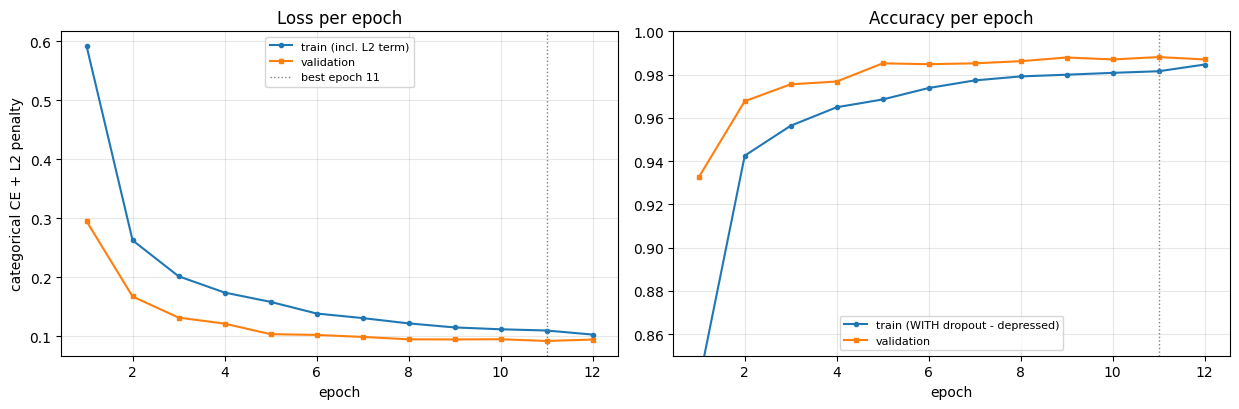

epoch 1 val acc here: 0.933 - the Stage 3c momentum transient shows as this first-epoch lag (and as the gap between the depressed train curve, which includes dropout, and everything else); it is a buffer warm-up, not an unstable model.


In [17]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
ep = np.arange(1, len(history.history["loss"]) + 1)
a1.plot(ep, history.history["loss"], marker="o", ms=3, label="train (incl. L2 term)")
a1.plot(ep, history.history["val_loss"], marker="s", ms=3, label="validation")
a1.axvline(best_epoch, ls=":", c="grey", lw=1, label=f"best epoch {best_epoch}")
a1.set(title="Loss per epoch", xlabel="epoch", ylabel="categorical CE + L2 penalty")
a1.legend(fontsize=8); a1.grid(alpha=.3)
a2.plot(ep, history.history["accuracy"], marker="o", ms=3,
        label="train (WITH dropout - depressed)")
a2.plot(ep, history.history["val_accuracy"], marker="s", ms=3, label="validation")
a2.axvline(best_epoch, ls=":", c="grey", lw=1)
a2.set(title="Accuracy per epoch", xlabel="epoch", ylim=(0.85, 1.0))
a2.legend(fontsize=8); a2.grid(alpha=.3)
plt.tight_layout(); plt.show()
e1 = history.history["val_accuracy"][0]
print(f"epoch 1 val acc here: {e1:.3f} - the Stage 3c momentum transient shows as this "
      f"first-epoch lag (and as the gap between the depressed train curve, which includes "
      f"dropout, and everything else); it is a buffer warm-up, not an unstable model.")

In [18]:
def report(tag, m, x, y_oh, y_hard):
    loss, acc = m.evaluate(x, y_oh, verbose=0)
    p = np.clip(m.predict(x, verbose=0), 1e-12, 1.0)
    ce = float(-np.mean(np.sum(y_oh * np.log(p), axis=1)))
    penalty = float(tf.add_n(m.losses)) if m.losses else 0.0
    pred = p.argmax(1)
    print(f"===== {tag} =====")
    print(f"loss {loss:.4f} = cross-entropy {ce:.4f} + L2 penalty {penalty:.4f} "
          f"(identity err {abs(loss - ce - penalty):.1e})")
    print(f"accuracy {acc * 100:.2f}%   ({int((pred == y_hard).sum())}/{len(y_hard)} correct)")
    return dict(tag=tag, loss=loss, ce=ce, l2=penalty, acc=acc, pred=pred)

r_fit  = report("TRAIN slice (20k this model fitted)", model, x_fit, y_fit, y_fit_hard)
r_val  = report("VALIDATION (10k, pool)", model, x_val, y_val, y_val_hard)
r_test = report("TEST (10k, never used for anything)", model, x_test, y_test, y_test_hard)
assert abs(r_test["loss"] - r_test["ce"] - r_test["l2"]) < 0.02   # penalty is data-free

print(f"\nfit-slice train {r_fit['acc']*100:.2f}% | val {r_val['acc']*100:.2f}% | "
      f"test {r_test['acc']*100:.2f}%")
print(f"train-test gap {(r_fit['acc'] - r_test['acc'])*100:+.2f} pp - the dropout-free "
      f"train number sits above the curve exactly as Stage 3d predicted")

===== TRAIN slice (20k this model fitted) =====
loss 0.0669 = cross-entropy 0.0150 + L2 penalty 0.0518 (identity err 6.7e-08)
accuracy 99.59%   (19918/20000 correct)


===== VALIDATION (10k, pool) =====
loss 0.0919 = cross-entropy 0.0400 + L2 penalty 0.0518 (identity err 2.0e-08)
accuracy 98.81%   (9881/10000 correct)


===== TEST (10k, never used for anything) =====
loss 0.0863 = cross-entropy 0.0345 + L2 penalty 0.0518 (identity err 3.7e-08)
accuracy 98.74%   (9874/10000 correct)

fit-slice train 99.59% | val 98.81% | test 98.74%
train-test gap +0.85 pp - the dropout-free train number sits above the curve exactly as Stage 3d predicted


Per-class behaviour on TEST:
              precision    recall  f1-score   support

           0      0.984     0.994     0.989       980
           1      0.993     0.994     0.993      1135
           2      0.983     0.988     0.986      1032
           3      0.995     0.987     0.991      1010
           4      0.995     0.983     0.989       982
           5      0.983     0.992     0.988       892
           6      0.988     0.984     0.986       958
           7      0.988     0.977     0.982      1028
           8      0.985     0.988     0.986       974
           9      0.979     0.987     0.983      1009

    accuracy                          0.987     10000
   macro avg      0.987     0.987     0.987     10000
weighted avg      0.987     0.987     0.987     10000



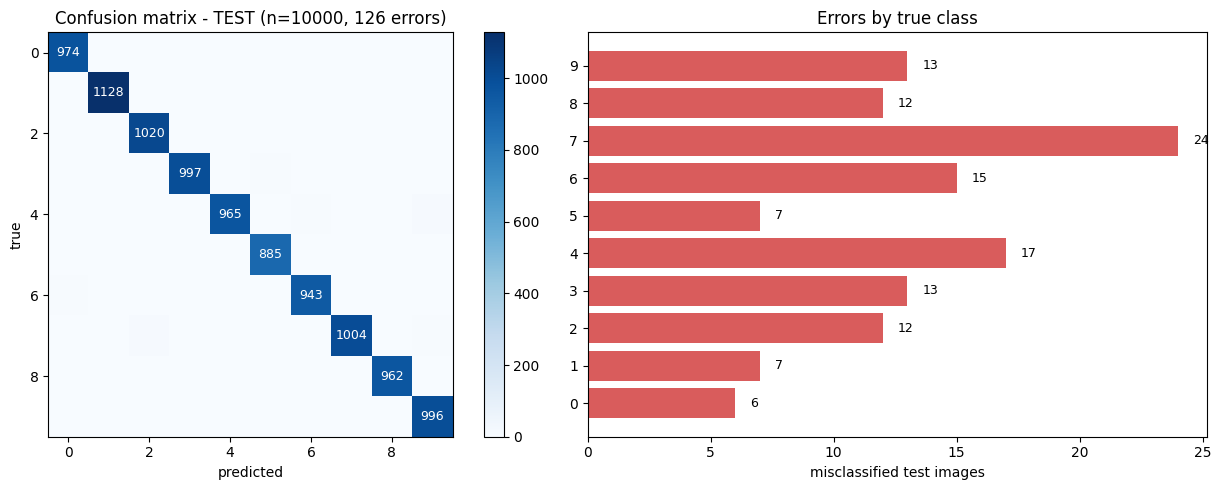

Top confusions (true -> predicted, count):
  7->2: 12, 4->9: 10, 3->5: 8, 6->0: 6, 7->9: 5


In [19]:
print("Per-class behaviour on TEST:")
print(classification_report(y_test_hard, r_test["pred"], digits=3))
cm = confusion_matrix(y_test_hard, r_test["pred"])
errs = cm.sum(1) - np.diag(cm)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5))
im = a1.imshow(cm, interpolation="nearest", cmap="Blues")
a1.set(title=f"Confusion matrix - TEST (n={cm.sum()}, {int(errs.sum())} errors)")
a1.set_xlabel("predicted"); a1.set_ylabel("true")
fig.colorbar(im, ax=a1, fraction=.046)
cut = cm.max() / 2.2
for i in range(10):
    for j in range(10):
        if cm[i, j] and (i == j or cm[i, j] > cut):
            a1.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > cut else "black")
a2.barh([str(i) for i in range(10)], errs, color="#d95c5c")
a2.set(title="Errors by true class", xlabel="misclassified test images")
for i, v in enumerate(errs):
    a2.text(v + .6, i, str(int(v)), va="center", fontsize=9)
plt.tight_layout(); plt.show()

off = cm.astype(float); np.fill_diagonal(off, 0)
pairs = sorted(((int(off[i, j]), i, j) for i in range(10) for j in range(10)), reverse=True)
print("Top confusions (true -> predicted, count):")
print("  " + ", ".join(f"{i}->{j}: {c}" for c, i, j in pairs[:5]))

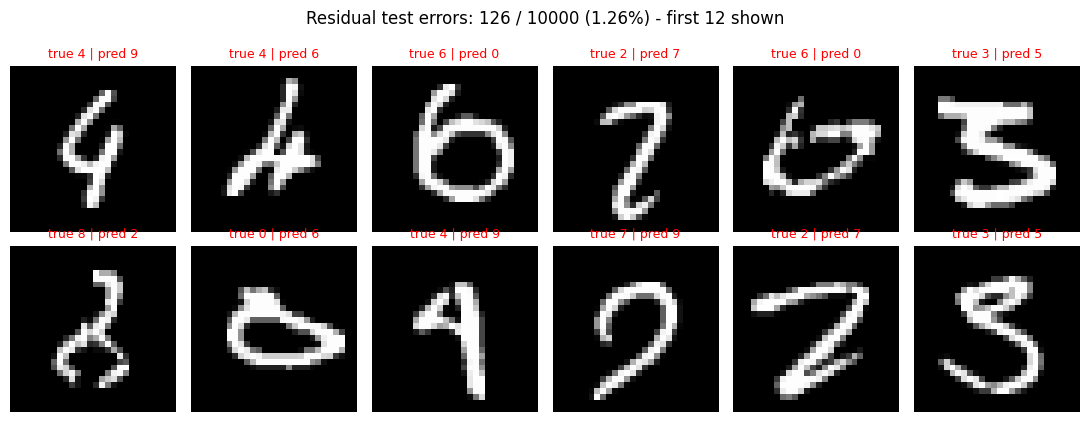

In [20]:
wrong = np.where(r_test["pred"] != y_test_hard)[0]
fig, axes = plt.subplots(2, 6, figsize=(11, 4.2))
for ax, idx in zip(axes.ravel(), wrong[:12]):
    ax.imshow(x_test_raw[idx], cmap="gray")
    ax.set_title(f"true {y_test_hard[idx]} | pred {r_test['pred'][idx]}",
                 fontsize=9, color="red")
    ax.axis("off")
for ax in axes.ravel()[len(wrong[:12]):]:
    ax.axis("off")
fig.suptitle(f"Residual test errors: {len(wrong)} / {len(y_test_hard)} "
             f"({len(wrong) / len(y_test_hard):.2%}) - first 12 shown", y=1.0)
plt.tight_layout(); plt.show()

## Do the regularisers earn their cost on the CNN?

Same `build_cnn`, same data, same seed — flip the two *weight-level* regularisers and the
spatial one together (`l2=None, dropout=None, spatial_dropout=None`); BatchNorm stays (like
the dense notebook, mixing its optimisation effect into a regularisation comparison would
blur two separate stories). Honest framing about the budget:

| row | model | fit set | epochs |
|---|---|---|---|
| reference (Stage 4) | full recipe | 20 000 | up to 12, early-stopped |
| without L2/SpatialDrop/Dropout | same builder, flags off | 12 000 | up to 8 |

The second row therefore runs **fewer samples and fewer epochs** than the reference, to keep
the whole notebook inside its time budget. That makes the gap column directionally
informative only. Read it together with the fit-set size printed underneath the table;
differences of a few tenths of a percentage point are well inside single-seed noise, so
what the row has to show is the *sign and rough size* of the train-test gap, not its last
decimal.

In [21]:
x_fit12, y_fit12 = x_train[:12_000], y_train[:12_000]
y_fit12_hard = y_train_raw[:12_000]

abl = [dict(config="reference: full Stage 4 recipe", fit_n=N_FIT,
            epochs=len(history.epoch),
            train=r_fit["acc"], val=r_val["acc"], test=r_test["acc"],
            gap_pp=(r_fit["acc"] - r_test["acc"]) * 100)]

m_off = compile_cnn(build_cnn(l2=None, dropout=None, spatial_dropout=None,
                              name="abl_no_regularisers"))
h_off = m_off.fit(x_fit12, y_fit12, batch_size=BATCH_SIZE, epochs=8, verbose=0,
                  validation_data=(x_val, y_val),
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",
                                                           patience=4,
                                                           restore_best_weights=True)])
_, tr_off = m_off.evaluate(x_fit12, y_fit12, verbose=0)
_, va_off = m_off.evaluate(x_val, y_val, verbose=0)
_, te_off = m_off.evaluate(x_test, y_test, verbose=0)
abl.append(dict(config="no L2 / SpatialDrop / Dropout", fit_n=12_000,
                epochs=len(h_off.epoch), train=tr_off, val=va_off, test=te_off,
                gap_pp=(tr_off - te_off) * 100))
print(f"regularisers-off model: its evaluate() loss is now pure CE (penalty sum "
      f"{float(tf.add_n(m_off.losses)) if m_off.losses else 0.0:.4f}) - do NOT compare "
      f"loss columns across rows; the accuracy columns are the comparable ones.")

tbl = pd.DataFrame(abl, columns=["config", "fit_n", "epochs", "train", "val", "test",
                                 "gap_pp"])
print()
print(tbl.to_string(index=False, float_format=lambda v: f"{v:9.4f}"))
tbl.to_csv("ablation_table.csv", index=False)
print("saved alongside as ablation_table.csv")

regularisers-off model: its evaluate() loss is now pure CE (penalty sum 0.0000) - do NOT compare loss columns across rows; the accuracy columns are the comparable ones.

                        config  fit_n  epochs     train       val      test    gap_pp
reference: full Stage 4 recipe  20000      12    0.9959    0.9881    0.9874    0.8500
 no L2 / SpatialDrop / Dropout  12000       8    1.0000    0.9853    0.9832    1.6800
saved alongside as ablation_table.csv


## Wrap-up

**Results at a glance** (this run, `SEED=42`; reruns move at most in the last decimal):

| metric | value |
|---|---|
| test accuracy (10k, untouched) | 98.74% — loss 0.0863 = CE 0.0345 + L2 0.0518 |
| validation accuracy (10k, pool) | 98.81% |
| fit-slice train accuracy, clean path | 99.59% — above the last curve epoch (0.985) by design: Stage 3d |
| train−test gap | +0.85 pp |
| parameters | 422,314 `count_params`; 421,866 trainable; 95% in the dense head |
| epochs run | 12 of 12 (best val_loss at epoch 11) — early stopping armed, not needed |
| momentum diagnostic, epoch-1 val acc | 0.925 (m=0.99) vs 0.933 (m=0.9) — ~1 pp warm-up lag; step-0 divisor error 2.3x/1.8x/2.1x (bn_1/bn_2/bn_head) |
| ablation (no L2/SpatialDrop/Dropout, 12k/8E) | train 100.0%, test 98.3%, gap 1.68 pp: memorised the fit set, generalised worse |

**What the four stages produced.**

| Stage | Outcome |
|---|---|
| 1 · Load | `(60000,28,28,1)` float32 in [0,1], one-hot labels; channel axis forced in |
| 2 · Model | Sequential CNN, 16 layers, 422,314 `count_params` — shape walk matched the `floor((H+2p−k)/s)+1` formula at every conv/pool; conv params provably size-independent; conv biases proven annihilated by BN |
| 3a · He Normal | fan_in = `kh·kw·C_in` at conv; kernel std ratios ≈1; RMS-through-ReLU ≈1 vs Glorot decay |
| 3b · L2 | evaluate-loss identity CE+λΣw² verified on untrained **and** trained weights; penalty data-free |
| 3c · BatchNorm | per-(N,H,W) per-channel stats verified; two code paths verified; momentum transient measured (epoch-1 lag of the 0.99 run vs the 0.9 clone; size scales with the step-0 divisor error, ~2x here) |
| 3d · Dropout | spatial = whole-channel all-or-nothing verified; inverted scaling verified; train-vs-inference path gap measured |
| 4 · Fit + evaluate | early-stopped; train/val/test reported with CE-vs-L2 split; confusion matrix; ablation |

**Verified pitfalls this run actually dodges** (all observed on TF 2.21 / Keras 3.15):

1. Keras 3 `Model.compile(optimizer, loss, loss_weights, metrics, ...)` — a *third
   positional* argument is `loss_weights`, not `metrics` (Keras 2 habit). Passing `["accuracy"]`
   positionally gives `dtype='string' is not a valid dtype for Keras type promotion`. Every
   compile here uses keywords.
2. `Sequential.layers` excludes the `InputLayer`: `layers[0]` is `conv_1`, index by name
   (`get_layer`) when it matters.
3. `l.activation` is a resolved *function* in Keras 3, so `l.activation == "relu"` is
   always `False`. The shape walk compares `l.get_config()["activation"]` strings instead.
4. `tf.reduce_std` does not exist — it is `tf.math.reduce_std`.
5. `model.summary()` has no `show_dtype` kwarg in Keras 3.
6. A model/layer name becomes a TF variable *scope*: no spaces (the builder slugifies).
7. `count_params()` excludes the `seed_generator_state` buffers — the raw variable sum
   exceeds it (measured above: 6 extra integers over 3 seeded dropout layers), and each is 2
   ints that are *state*, not parameters.
8. The test set was touched once, in Stage 4, after the last weight update. Nothing in this
   notebook turned a knob to chase the test number.

**Where to go next, in order of information-per-minute:** data augmentation
(`RandomRotation`/`RandomZoom`) before anything else — MNIST's residual errors are shifts
and rotations, and no regulariser buys as much; then drop the `Flatten` head entirely for a
conv-only global-average-pool variant and compare parameters/accuracy (the walk showed the
head owns 95% of the weights); `ReduceLROnPlateau` if you raise `EPOCHS`; `momentum` tuning
only if you shorten runs; and multi-seed repeats before believing any difference under
~0.5 pp — this whole notebook is a single seed telling a *directional* story. A natural
follow-up experiment: the same four stages with `use_bn=False` but He + L2 + dropout kept —
Stage 3c showed BN and its buffers are load-bearing for the schedule, and switching it off
makes the training curve honest but slow.